# Analysis of Chemical Components in Cosmetics
**TR-102 Industrial Training Project | Data Analytics | Mentor: MadTourEasy**

**Students




:** Ishmeet Singh Chadha, Bhagatpreet Singh, Diwanshu Singla
**Training period:** 22 June 2026 – 21 July 2026  
**Dataset:** `cosmetics(1).csv` (1,472 products, 11 source columns)

## Project overview
This notebook explores cosmetic products by category, brand, price, rating, skin-type suitability flags, and ingredient lists. It includes data quality checks, exploratory data analysis, ingredient-frequency analysis, a content-based similarity demonstration, and exports for Power BI.

> **Interpretation and safety note:** Skin-type flags and product ratings are fields in the supplied dataset, not medical evidence. Similar ingredient lists do not establish safety, efficacy, allergy risk, or personal suitability. The similarity section is exploratory and should not be treated as a medical recommendation.


In [1]:
# 1. Imports and configuration
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.manifold import TSNE
from IPython.display import display

DATA_PATH = Path("C:/Users/ACER/Downloads/dataset/datasets/cosmetics.csv")  # In Colab, upload this file or change the path.
OUTPUT_DIR = Path("powerbi_exports")
OUTPUT_DIR.mkdir(exist_ok=True)


In [2]:
# 2. Load and inspect the data
df_raw = pd.read_csv(DATA_PATH)
print(f"Rows: {df_raw.shape[0]:,} | Columns: {df_raw.shape[1]}")
display(df_raw.head())
display(pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing_values": df_raw.isna().sum(),
    "unique_values": df_raw.nunique(dropna=True)
}))


Rows: 1,472 | Columns: 11


,Label,Brand,Name,Price,Rank,Ingredients,Combination,Dry,Normal,Oily,Sensitive
0,Moisturizer,LA MER,Crème de la Mer,175,4.1,"Algae (Seaweed) Extract, Mineral Oil, Petrolat...",1,1,1,1,1
1,Moisturizer,SK-II,Facial Treatment Essence,179,4.1,"Galactomyces Ferment Filtrate (Pitera), Butyle...",1,1,1,1,1
2,Moisturizer,DRUNK ELEPHANT,Protini™ Polypeptide Cream,68,4.4,"Water, Dicaprylyl Carbonate, Glycerin, Ceteary...",1,1,1,1,0
3,Moisturizer,LA MER,The Moisturizing Soft Cream,175,3.8,"Algae (Seaweed) Extract, Cyclopentasiloxane, P...",1,1,1,1,1
4,Moisturizer,IT COSMETICS,Your Skin But Better™ CC+™ Cream with SPF 50+,38,4.1,"Water, Snail Secretion Filtrate, Phenyl Trimet...",1,1,1,1,1


,dtype,missing_values,unique_values
Label,str,0,6
Brand,str,0,116
Name,str,0,1472
Price,int64,0,146
Rank,float64,0,29
Ingredients,str,0,1334
Combination,int64,0,2
Dry,int64,0,2
Normal,int64,0,2
Oily,int64,0,2


In [3]:
# 3. Clean types and standardize text
df = df_raw.copy()
text_cols = ["Label", "Brand", "Name", "Ingredients"]
for col in text_cols:
    df[col] = df[col].fillna("").astype(str).str.strip()

for col in ["Price", "Rank"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

skin_cols = ["Combination", "Dry", "Normal", "Oily", "Sensitive"]
for col in skin_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0).astype(int)

df["IngredientCount"] = df["Ingredients"].apply(
    lambda value: len([item for item in value.split(",") if item.strip()])
)
df["PriceBand"] = pd.cut(
    df["Price"], bins=[-np.inf, 25, 50, 100, np.inf],
    labels=["≤ $25", "$25–$50", "$50–$100", "> $100"]
).astype("string")

print("Duplicate full rows:", int(df.duplicated().sum()))
print("Missing values after cleaning:")
display(df.isna().sum().to_frame("Missing"))


Duplicate full rows: 0
Missing values after cleaning:


,Missing
Label,0
Brand,0
Name,0
Price,0
Rank,0
Ingredients,0
Combination,0
Dry,0
Normal,0
Oily,0


## 4. Dataset profile and quality checks
The supplied file contains product metadata and binary flags for five skin types. Validate values and missingness before interpreting the results. Price currency is not explicitly defined in the supplied CSV, so do not label it as USD/INR in the dashboard unless the data provider confirms the currency.

In [4]:
# 4.1 Summary statistics
display(df[["Price", "Rank", "IngredientCount"]].describe().T)
display(df["Label"].value_counts().rename_axis("Category").to_frame("ProductCount"))
display(df["Brand"].value_counts().head(15).rename_axis("Brand").to_frame("ProductCount"))


,count,mean,std,min,25%,50%,75%,max
Price,1472.0,55.584239,45.014429,3.0,30.00,42.5,68.0,370.0
Rank,1472.0,4.153261,0.633918,0.0,4.00,4.3,4.5,5.0
IngredientCount,1472.0,31.122283,22.395372,1.0,17.75,30.0,42.0,220.0


,ProductCount
Category,
Moisturizer,298
Cleanser,281
Face Mask,266
Treatment,248
Eye cream,209
Sun protect,170


,ProductCount
Brand,
CLINIQUE,79
SEPHORA COLLECTION,66
SHISEIDO,63
ORIGINS,54
MURAD,47
KIEHL'S SINCE 1851,46
PETER THOMAS ROTH,46
FRESH,44
DR. JART+,41


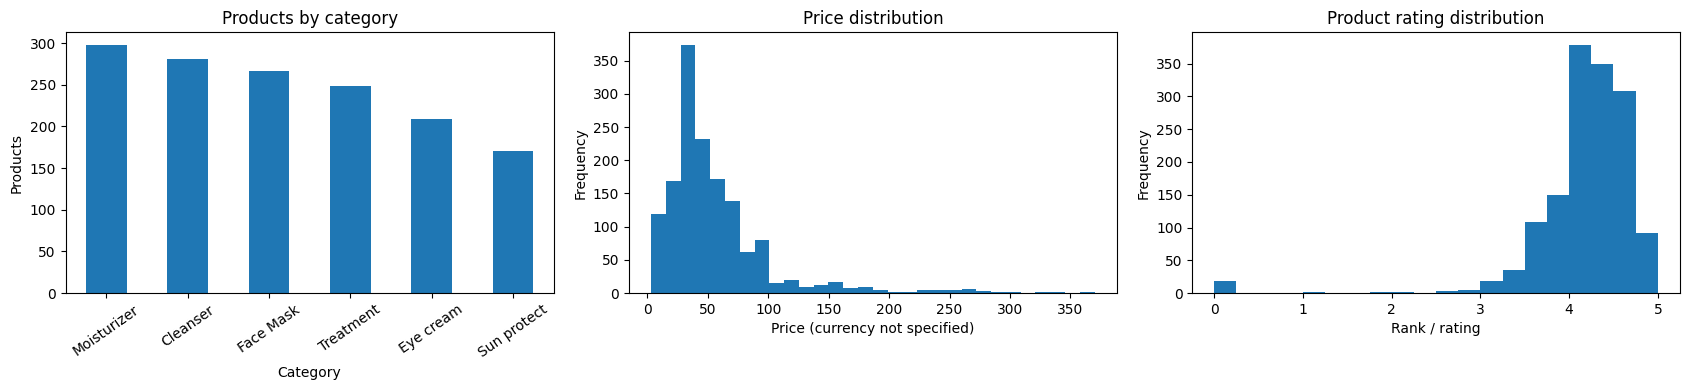

In [5]:
# 5. Exploratory data analysis
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
df["Label"].value_counts().plot(kind="bar", ax=axes[0], title="Products by category")
axes[0].set_xlabel("Category"); axes[0].set_ylabel("Products"); axes[0].tick_params(axis="x", rotation=35)
df["Price"].dropna().plot(kind="hist", bins=30, ax=axes[1], title="Price distribution")
axes[1].set_xlabel("Price (currency not specified)")
df["Rank"].dropna().plot(kind="hist", bins=20, ax=axes[2], title="Product rating distribution")
axes[2].set_xlabel("Rank / rating")
plt.tight_layout()
plt.show()


In [6]:
# 5.1 Category-level metrics
category_summary = (df.groupby("Label", as_index=False)
    .agg(ProductCount=("Name", "count"),
         AveragePrice=("Price", "mean"),
         MedianPrice=("Price", "median"),
         AverageRating=("Rank", "mean"),
         AverageIngredientCount=("IngredientCount", "mean"))
    .round(2).sort_values("ProductCount", ascending=False))
display(category_summary)


,Label,ProductCount,AveragePrice,MedianPrice,AverageRating,AverageIngredientCount
3,Moisturizer,298,69.09,50.0,4.24,33.76
0,Cleanser,281,32.60,28.0,4.31,24.70
2,Face Mask,266,42.62,36.0,4.17,31.42
5,Treatment,248,79.18,64.5,4.22,32.76
1,Eye cream,209,63.60,52.0,3.81,35.74
4,Sun protect,170,45.91,38.0,4.05,28.58


,SkinType,SuitableProductCount,AveragePrice,AverageRating
0,Combination,966,55.99,4.17
1,Dry,904,57.92,4.17
2,Normal,960,57.20,4.18
3,Oily,894,55.73,4.16
4,Sensitive,756,55.92,4.16


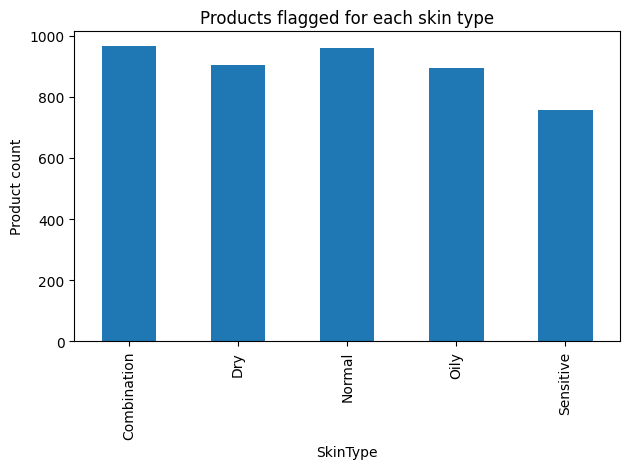

In [7]:
# 5.2 Skin-type coverage
skin_summary = pd.DataFrame([
    {"SkinType": skin, "SuitableProductCount": int(df[skin].eq(1).sum()),
     "AveragePrice": round(df.loc[df[skin].eq(1), "Price"].mean(), 2),
     "AverageRating": round(df.loc[df[skin].eq(1), "Rank"].mean(), 2)}
    for skin in skin_cols
])
display(skin_summary)
skin_summary.set_index("SkinType")["SuitableProductCount"].plot(kind="bar", title="Products flagged for each skin type")
plt.ylabel("Product count"); plt.tight_layout(); plt.show()


## 6. Ingredient analysis
Ingredient names are normalized to lowercase and split on commas. This is a practical first pass; ingredient spelling variants, synonyms, and formulation-specific naming may remain. Frequency means the number of product ingredient lists mentioning a token, not its concentration or effect.

,Ingredient,ProductMentions
0,water,995
1,glycerin,980
2,phenoxyethanol,806
3,butylene glycol,788
4,disodium edta,547
5,sodium hyaluronate,476
6,caprylyl glycol,461
7,dimethicone,442
8,xanthan gum,416
9,tocopheryl acetate,415


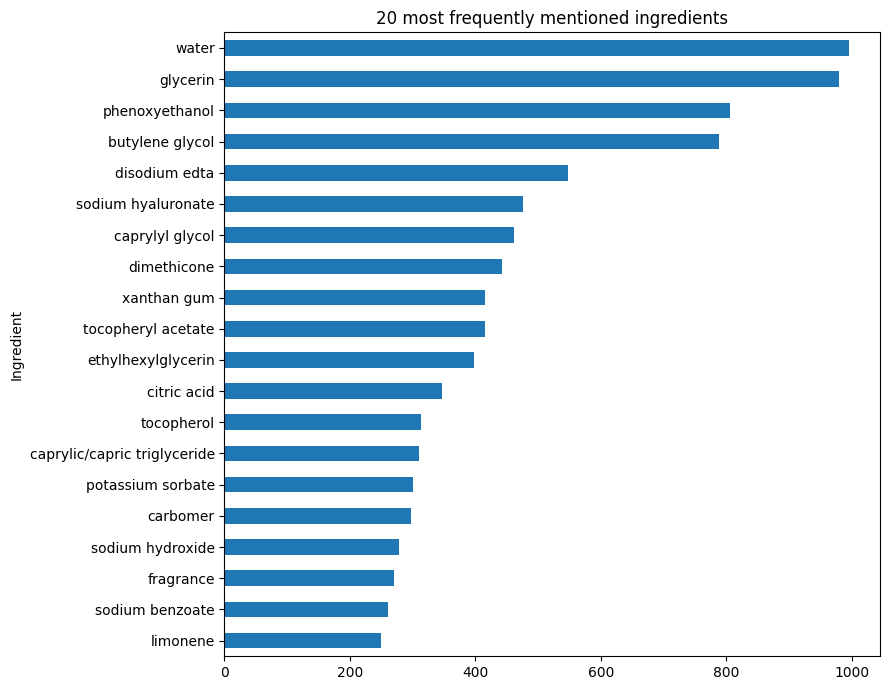

In [8]:
from collections import Counter
ingredient_counter = Counter()
for ingredient_list in df["Ingredients"]:
    ingredient_counter.update(
        token.strip().lower() for token in ingredient_list.split(",") if token.strip()
    )
ingredient_frequency = pd.DataFrame(
    ingredient_counter.most_common(), columns=["Ingredient", "ProductMentions"]
)
display(ingredient_frequency.head(20))
ingredient_frequency.head(20).sort_values("ProductMentions").plot(
    x="Ingredient", y="ProductMentions", kind="barh", legend=False,
    title="20 most frequently mentioned ingredients", figsize=(9, 7)
)
plt.tight_layout(); plt.show()


## 7. Content-based ingredient similarity
TF-IDF vectorization reduces the influence of ingredients that occur in nearly every product. Cosine similarity then compares ingredient-list vectors. The output is an exploratory similarity score, not a product-quality or safety score.

In [9]:
# Limit to products with non-empty ingredient lists
similarity_df = df.loc[df["Ingredients"].str.strip().ne("")].copy().reset_index(drop=True)
vectorizer = TfidfVectorizer(
    tokenizer=lambda text: [t.strip().lower() for t in text.split(",") if t.strip()],
    token_pattern=None,
    lowercase=False,
    min_df=2
)
X = vectorizer.fit_transform(similarity_df["Ingredients"])
print("Products encoded:", X.shape[0], "| Ingredient features:", X.shape[1])


Products encoded: 1472 | Ingredient features: 2909


In [10]:
def find_similar_products(product_name, top_n=5):
    matches = similarity_df.index[similarity_df["Name"].str.casefold() == product_name.casefold()].tolist()
    if not matches:
        raise ValueError(f"Product not found: {product_name!r}. Try a name shown in similarity_df['Name'].")
    idx = matches[0]
    scores = cosine_similarity(X[idx], X).ravel()
    scores[idx] = -1  # exclude the selected product itself
    best = np.argsort(scores)[::-1][:top_n]
    cols = ["Name", "Brand", "Label", "Price", "Rank", "IngredientCount"]
    result = similarity_df.loc[best, cols].copy()
    result["IngredientSimilarity"] = scores[best].round(3)
    return result.reset_index(drop=True)

# Example: choose the first product with a non-empty ingredient list.
example_product = similarity_df.iloc[0]["Name"]
print("Example product:", example_product)
display(find_similar_products(example_product, top_n=5))


Example product: Crème de la Mer


,Name,Brand,Label,Price,Rank,IngredientCount,IngredientSimilarity
0,Little Miss Miracle Limited-Edition Crème de l...,LA MER,Moisturizer,325,5.0,42,1.000
1,Crème de la Mer Mini,LA MER,Moisturizer,85,4.1,42,1.000
2,The Tonic,LA MER,Cleanser,95,4.1,35,0.425
3,The Cleansing Micellar Water,LA MER,Cleanser,95,4.5,41,0.400
4,The Moisturizing Matte Lotion,LA MER,Moisturizer,270,3.9,74,0.378


## 8. Optional t-SNE visualization
t-SNE is stochastic and its axes have no direct business meaning. Use it only as a visual exploration of local ingredient-profile similarity; do not interpret distances as calibrated scores. If the dataset is large, this step can take longer than the summary analysis.

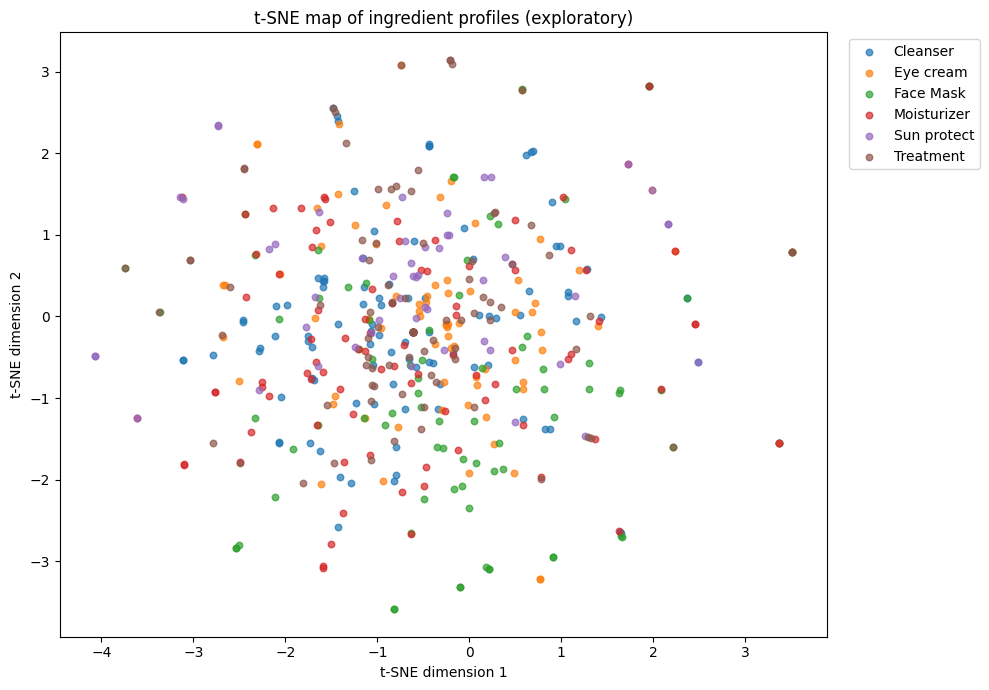

In [11]:
# Run only when needed; set random_state for reproducibility.
sample_n = min(500, X.shape[0])
rng = np.random.RandomState(42)
sample_idx = rng.choice(X.shape[0], size=sample_n, replace=False) if sample_n < X.shape[0] else np.arange(X.shape[0])
X_sample = X[sample_idx]
perplexity = min(30, max(5, (sample_n - 1) // 3))
tsne = TSNE(n_components=2, random_state=42, init="random",
            learning_rate="auto", perplexity=perplexity)
coords = tsne.fit_transform(X_sample.toarray())
plot_df = similarity_df.iloc[sample_idx][["Name", "Brand", "Label", "Price", "Rank"]].copy()
plot_df["TSNE_1"] = coords[:, 0]
plot_df["TSNE_2"] = coords[:, 1]
fig, ax = plt.subplots(figsize=(10, 7))
for category, group in plot_df.groupby("Label"):
    ax.scatter(group["TSNE_1"], group["TSNE_2"], s=22, alpha=.7, label=category)
ax.set_title("t-SNE map of ingredient profiles (exploratory)")
ax.set_xlabel("t-SNE dimension 1"); ax.set_ylabel("t-SNE dimension 2")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()


## 9. Export Power BI tables
These CSV files are designed for import into Power BI Desktop. Keep `Products_Clean` as the primary product table and use the summary tables for validated report visuals. Refresh the exports after changing the source data.

In [12]:
# Create Power BI-ready exports
export_df = df.copy()
export_df.to_csv(OUTPUT_DIR / "Products_Clean.csv", index=False)

category_summary.to_csv(OUTPUT_DIR / "Category_Summary.csv", index=False)
skin_summary.to_csv(OUTPUT_DIR / "SkinType_Summary.csv", index=False)
ingredient_frequency.to_csv(OUTPUT_DIR / "Ingredient_Frequency.csv", index=False)

brand_summary = (df.groupby("Brand", as_index=False)
    .agg(ProductCount=("Name", "count"), AveragePrice=("Price", "mean"),
         AverageRating=("Rank", "mean"))
    .round(2).sort_values("ProductCount", ascending=False))
brand_summary.to_csv(OUTPUT_DIR / "Brand_Summary.csv", index=False)

print("Exported files:")
for file in sorted(OUTPUT_DIR.glob("*.csv")):
    print(file, file.stat().st_size, "bytes")


Exported files:
powerbi_exports\Brand_Summary.csv 2993 bytes
powerbi_exports\Category_Summary.csv 304 bytes
powerbi_exports\Ingredient_Frequency.csv 213488 bytes
powerbi_exports\Products_Clean.csv 1169372 bytes
powerbi_exports\SkinType_Summary.csv 175 bytes


## 10. Findings, limitations, and conclusion
Write the final findings after running all cells and reviewing the actual output tables. Distinguish observed patterns from explanations. The dataset does not provide product sales, customer purchases, ingredient concentrations, verified currency, or clinical outcomes, so the analysis cannot establish demand, affordability in a particular currency, safety, or medical suitability.

### Future scope
- Validate product currency, data provenance, and rating definitions with the provider.
- Normalize ingredient synonyms and spelling variants.
- Add verified ingredient taxonomy and allergen/reference metadata.
- Build a user-facing recommender only after adding user preferences and explicit safety controls.
- Refresh data and dashboard exports through a documented repeatable workflow.
